<div style="text-align:center">
  <img src="https://www.deparakademi.com.tr/wp-content/uploads/2022/05/Depar-Akademi-Logo.png.webp" width="300">
</div>


<font color="#4d77cf">**Dr.Bülent Çobanoğlu**</font>


## İçindekiler
1. Set
2. Frozenset
3. Dict
4. Nested Dict
5. List, Dict yapılarında min - max işlemleri
6. pandas ile veri yapılarını Tabloya Dönüştürme
7. Tablodan veri yapılarına dönüşüm
8. Mutable | Immutable
9. reduce, filter, map() fonksiyonları
10. enumerate()
11. def ile fonksiyon tanımlama
12. return kullanımı
13. Lambda fonksiyonları
14. Liste Üreteçleri
15. Hata Yakalama(try, except, final,...)



# Sözlük(dict) veri yapısı


*   {...}
*   dict()



#sözlük metotları
https://docs.python.org/3/builtins/stdtypes.html#dict

# 📘 Python `dict` (Sözlük) Metotları


| Metot / İşlem | Ne yapar? | Dönüş |
|---|---|---|
| `d[k]` | Değeri okur (yoksa `KeyError`) | değer |
| `d[k] = v` | Ekler / günceller | – |
| `del d[k]` | Siler (yoksa `KeyError`) | – |
| `k in d` | Anahtar var mı? | `bool` |
| `len(d)` | Çift sayısı | `int` |
| `iter(d)`, `reversed(d)` | Anahtarlar üzerinde gezinme (ters: 3.8+) | iterator |
| `d.get(k, varsayılan)` | Güvenli okuma | değer / varsayılan |
| `d.keys()` | Anahtar görünümü | view |
| `d.values()` | Değer görünümü | view |
| `d.items()` | `(anahtar, değer)` görünümü | view |
| `d.update(...)` | Sözlüğü günceller veya başkası ile birleştirir | `None` |
| `d.setdefault(k, v)` | k varsa değerini döndürür yoksa ekler | değer |
| `d.pop(k[, varsayılan])` | Siler ve değeri döndürür | değer |
| `d.popitem()` | Son eklenen çifti siler (LIFO) | `(k, v)` |
| `d.clear()` | Hepsini siler | `None` |
| `d.copy()` | Yüzeysel (shallow) kopya | `dict` |
| `dict.fromkeys(it, v)` | Anahtar listesinden yeni dict | `dict` |
| `d \| other`, `d \|= other` | Birleştirme (3.9+) | `dict` |

> 💡 Yerinde değişiklik yapan metotlar (`update`, `clear` ...) **`None`** döndürür. `d = d.update(...)` yazmak sözlüğünüzü `None` yapar!

In [1]:
d = {"a": 1, "b": 2, "c": 3}
k, v, it = d.keys(), d.values(), d.items()
print(k)
print(v)
print(it)

dict_keys(['a', 'b', 'c'])
dict_values([1, 2, 3])
dict_items([('a', 1), ('b', 2), ('c', 3)])


In [2]:
list(k)

['a', 'b', 'c']

In [3]:
# sözlük güncelleme
d["d"] = 4
print(list(k))            # 'd' görünüme otomatik yansıdı
print(list(v))
print(list(it))

['a', 'b', 'c', 'd']
[1, 2, 3, 4]
[('a', 1), ('b', 2), ('c', 3), ('d', 4)]


In [4]:
g = dict.fromkeys(["ad", "yas"]) # otomatik sözlük oluşturma
g

{'ad': None, 'yas': None}

In [5]:
g["ad"] = "ali"
g["yas"] = 34
g["tel"] = 545234
print(g)

{'ad': 'ali', 'yas': 34, 'tel': 545234}


In [95]:
# iki listeyi zipleyip, sözlüğe dönüştürme
keys = ["ad", "yas", "tel"]
values = ["ali", 34, 545234]
sozluk = dict(zip(keys, values))
print(sozluk)

{'ad': 'ali', 'yas': 34, 'tel': 545234}


In [7]:
# Çoklu silme: 1.yöntem listeye dönüştür sil
sozluk = {"a": 1, "b": 2, "c": 3, "d":4, "e":5}
# listeye dönüştür ve del ile sil
list_sozluk = list(sozluk.items())
print(list_sozluk)
# b,c ve d elemalarını sil
del list_sozluk[1:4]  # dilimleme yaparak sildik
print(list_sozluk)
# tekrar sözlüğe dönüştür
sozluk = dict(list_sozluk)
print(sozluk)

[('a', 1), ('b', 2), ('c', 3), ('d', 4), ('e', 5)]
[('a', 1), ('e', 5)]
{'a': 1, 'e': 5}


In [8]:
# Çoklu silme: 2.yöntem del
sozluk = {"a": 1, "b": 2, "c": 3, "d":4, "e":5}
# listeye dönüştür ve del ile sil
del sozluk["b"], sozluk["c"], sozluk["d"]
print(sozluk)

{'a': 1, 'e': 5}


In [9]:
# Çoklu silme: 3.yöntem döngü ve del
sozluk = {"a": 1, "b": 2, "c": 3, "d":4, "e":5}
# listeye dönüştür ve del ile sil
sil_list = ["b", "c", "d"]
for i in sil_list:
    del sozluk[i]

print(sozluk)

{'a': 1, 'e': 5}


In [13]:
sozluk2 = dict(**{"a": 1}, **{"b": 2}, **{"c": 3}, d=4, e=5)

print(sozluk2)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5}


In [47]:
# iç içe sözlük
rehber = {'aile':{'anne_tarafi':{'teyze':{'ayşe':123,'fatma':456,'kıymet':789},
                                 'dayi':{'celil':545,'dursun':533,'hakkı':234}
                                },
                  'baba_tarafi':{'hala':{'sultan':567,'derya':678},
                                 'amca':{'şükrü':234,'zamir':679}}
                  },

          'arkadas':{'mahalle': {'ali':3456,'osman':4567},
                     'is':{'esra':5678, 'ahmet':7890}
                    }
          }

print(rehber)

{'aile': {'anne_tarafi': {'teyze': {'ayşe': 123, 'fatma': 456, 'kıymet': 789}, 'dayi': {'celil': 545, 'dursun': 533, 'hakkı': 234}}, 'baba_tarafi': {'hala': {'sultan': 567, 'derya': 678}, 'amca': {'şükrü': 234, 'zamir': 679}}}, 'arkadas': {'mahalle': {'ali': 3456, 'osman': 4567}, 'is': {'esra': 5678, 'ahmet': 7890}}}


In [45]:
# nested dict yapısında bir veriye erişim: celil dayının telefonuna erişme
rehber['aile']['anne_tarafi']['dayi']['celil']

545

In [46]:
#işten ahmet telefonuna erişim
rehber['arkadas']['is']['ahmet']

7890

# Sözlükten tabloya dönüşüm

In [89]:
!pip install pandas

In [101]:
import pandas as pd
# Sözlük içinde Liste Yapısı (her key(anahtar) sütun adı olur....)
veri = {
    "isim": ["Ayşe", "Mehmet", "Zeynep"],
    "yas": [25, 30, 22],
    "sehir": ("Ankara", "İstanbul", "Sakarya")
    }

df = pd.DataFrame(veri)
df

,isim,yas,sehir
0,Ayşe,25,Ankara
1,Mehmet,30,İstanbul
2,Zeynep,22,Sakarya


In [99]:
import pandas as pd
# Liste içinde Sözlük Yapısı: her key/anahtar bir sütun
# Ve her sözlük value'su satır/kayıt olmuş
veri = [
    {"isim": "Ayşe", "yas": 25, "sehir": "Ankara"}, # 1.kayıt
    {"isim": "Mehmet", "yas": 30, "sehir": "İstanbul"}, # 2.kayıt
    {"isim": "Zeynep", "yas": 22, "sehir": "Sakarya"}
]

df = pd.DataFrame(veri)
df

,isim,yas,sehir
0,Ayşe,25,Ankara
1,Mehmet,30,İstanbul
2,Zeynep,22,Sakarya


In [100]:
# İç içe sözlük (iç anahtarlar satır indeksi olur)
nested = {
    "mat":   {"Ali": 80, "Ayşe": 95, "Can": 60},
    "fizik": {"Ali": 70, "Ayşe": 85, "Can": 75},
}
df5 = pd.DataFrame(nested)
print(df5)


      mat  fizik
Ali    80     70
Ayşe   95     85
Can    60     75


In [102]:
# eksik verileri NaN ile doldurur
satirlar = [
    {"isim": "Ayşe",   "yas": 25, "sehir": "Ankara"},
    {"isim": "Mehmet", "yas": 30},                       # 'sehir' eksik -> NaN
    {"isim": "Zeynep", "sehir": "Sakarya"},              # 'yas' eksik   -> NaN
]
df2 = pd.DataFrame(satirlar)
df2

,isim,yas,sehir
0,Ayşe,25.0,Ankara
1,Mehmet,30.0,NaN
2,Zeynep,NaN,Sakarya


In [ ]:
# Pythondaki 'None' karşılığı pandas de 'NaN' verisidir.
# Farkı: pandas NaN değerlerinin tipi float dur.

In [104]:
type(None)

NoneType

In [105]:
import numpy as np
type(np.nan)

float

In [108]:
# tüm tabloyu yaşa göre sırala
df.sort_values(by='yas')

,isim,yas,sehir
2,Zeynep,22,Sakarya
0,Ayşe,25,Ankara
1,Mehmet,30,İstanbul


In [109]:
# tüm tabloyu yaşa göre büyükten küçüğe sırala
df.sort_values(by='yas', ascending=False)

,isim,yas,sehir
1,Mehmet,30,İstanbul
0,Ayşe,25,Ankara
2,Zeynep,22,Sakarya


In [106]:
import tabulate as tb
veri = {
    "isim": ["Ayşe", "Mehmet", "Zeynep"],
    "yas": [25, 30, 22],
    "sehir": ["Ankara", "İstanbul", "Sakarya"]
    }

tablo = tb.tabulate(veri, headers="keys", tablefmt="fancy_grid")
print(tablo)

╒════════╤═══════╤══════════╕
│ isim   │   yas │ sehir    │
╞════════╪═══════╪══════════╡
│ Ayşe   │    25 │ Ankara   │
├────────┼───────┼──────────┤
│ Mehmet │    30 │ İstanbul │
├────────┼───────┼──────────┤
│ Zeynep │    22 │ Sakarya  │
╘════════╧═══════╧══════════╛


In [107]:
tablo = tb.tabulate(veri, headers="keys")
print(tablo)

isim      yas  sehir
------  -----  --------
Ayşe       25  Ankara
Mehmet     30  İstanbul
Zeynep     22  Sakarya


In [112]:
#iç içe listeden tabloya dönüşüm
import pandas as pd
veri = [
    ["Ayşe", 25, "Ankara"],
    ["Mehmet", 30, "İstanbul"],
    ["Zeynep", 22, "Sakarya"]
]

df = pd.DataFrame(veri, columns=["isim", "yas", "sehir"])
df

,isim,yas,sehir
0,Ayşe,25,Ankara
1,Mehmet,30,İstanbul
2,Zeynep,22,Sakarya


In [111]:
# bir sütunu index yapmak
df = df.set_index("isim")
print(df)

        yas     sehir
isim                 
Ayşe     25    Ankara
Mehmet   30  İstanbul
Zeynep   22   Sakarya


In [113]:
#Tabloyu tekrar Python veri yapılarına (list, dict) çevirme
print(df.to_dict())                       # sütun yönlü


{'isim': {0: 'Ayşe', 1: 'Mehmet', 2: 'Zeynep'}, 'yas': {0: 25, 1: 30, 2: 22}, 'sehir': {0: 'Ankara', 1: 'İstanbul', 2: 'Sakarya'}}


In [114]:
print(df.to_dict(orient="records"))       # satır yönlü (sözlükler listesi)


[{'isim': 'Ayşe', 'yas': 25, 'sehir': 'Ankara'}, {'isim': 'Mehmet', 'yas': 30, 'sehir': 'İstanbul'}, {'isim': 'Zeynep', 'yas': 22, 'sehir': 'Sakarya'}]


In [115]:
print(df.values.tolist())                # listeler listesi
print(df["yas"].tolist())                # tek sütun -> liste

[['Ayşe', 25, 'Ankara'], ['Mehmet', 30, 'İstanbul'], ['Zeynep', 22, 'Sakarya']]
[25, 30, 22]


In [116]:
df.to_numpy() #numpy dizisine/array dönüştür

array([['Ayşe', 25, 'Ankara'],
       ['Mehmet', 30, 'İstanbul'],
       ['Zeynep', 22, 'Sakarya']], dtype=object)

## Veri Yapılarında min(), max() işlemleri

In [14]:
listem = [10,37,32,78,98,12,5,6,7]
min(listem)  # listedeki en küçük değeri ver

5

In [15]:
min(5,2,6)

2

In [16]:
listem = [10,37,32,78,98,12,5,6,7]
max(listem)  # listedeki en büyük değeri ver

98

In [17]:
demet = (10,37,32,78,98,12,5,6,7)
min(demet)  # listedeki en küçük değeri ver

5

In [22]:
# esasen ASCII tablosundaki sıraya bakarak min-max işlemleri yapılır
str_list = ["cansu", "mustafa", "eyüp", "nurefşan", "su", "aleyna", "Zeynep"]
min(str_list)  # listedeki en küçük değeri ver

'Zeynep'

In [25]:
# esasen ASCII tablosundaki sıraya bakarak min-max işlemleri yapılır
str_list = ["cansu", "mustafa", "eyüp", "nurefşan", "su", "aleyna", "zeynep"]
min(str_list)  # listedeki en küçük değeri ver
#

'aleyna'

In [27]:
# listedeki en uzun ismi ver
max(str_list, key=len)  # elemanların karakter sayısına göre min-max

'nurefşan'

In [28]:
# listedeki en kısa ismi ver
min(str_list, key=len)  # elemanların karakter sayısına göre min-max

'su'

In [29]:
min(range(1,9))

1

In [30]:
max(range(1,9))

8

In [32]:
nots = {"cansu":67, "mustafa":89, "eyüp":45, "nurefşan":60, "su":90, "aleyna":86, "zeynep":35}
# en düşük ve en yüksek notlar kime ait
# min(nots)  # key'lere göre minimumu alır
min(nots, key=nots.get)  # get ile value'su en küçük olan key'i döndürür.

'zeynep'

In [33]:
min(nots, key=nots.__getitem__)  # get ile value'su en küçük olan key'i döndürür.

'zeynep'

In [35]:
# en yüksek not kime ait
max(nots, key = nots.get)

'su'

In [ ]:
nots = {"cansu":67, "mustafa":89, "eyüp":45, "nurefşan":60, "su":90, "aleyna":86, "zeynep":35}
nots.popitem() # sözlükten en son elemanı siler

In [ ]:
nots

In [ ]:
nots.setdefault("zeyno", 45)

In [ ]:
nots

In [ ]:
# sözlük birleştirme |
a = {'one':1, 'two':2}
b = {'three':3, 'fourt':4}
c = a|b # yeni bir sözlük oluşturduk
print(c)
#

In [ ]:
a|=b # güncelle
print(a)

# Set (Küme) Veri Yapısı


*   set()
*   {}



**Set**, benzersiz (tekrarsız) elemanlardan oluşan, **sırasız** ve **değiştirilebilir (mutable)** bir veri yapısıdır.

Özellikleri:
- Elemanlar **tekrar edemez**.
- Elemanlar **sırasızdır**, indeks ile erişilemez (`s[0]` hata verir).
- Elemanlar **hashable (immutable)** olmalıdır: `int`, `str`, `tuple` olabilir; `list`, `dict`, `set` olamaz.
- Üyelik kontrolü (`in`) çok hızlıdır.

In [48]:
bos_kume = set()
type(bos_kume)

set

In [49]:
bos_sozluk = {}  #boş küme olmaz, dict tanımlamasıdır
type(bos_sozluk)

dict

In [50]:
kume = {"mavi", "sarı", "yeşil", "mavi"}
type(kume)

set

In [51]:
len(kume)  # tekrarlar sayılmaz

3

In [52]:
print(kume)

{'sarı', 'yeşil', 'mavi'}


In [53]:
kume = {"mavi", "sarı", "yeşil", "mavi"}
liste = ["mavi", "sarı", "yeşil", "mavi"]
print(len(kume))
print(len(liste))

3
4


In [54]:
dir(set)[-17:] # küme metotları

['add',
 'clear',
 'copy',
 'difference',
 'difference_update',
 'discard',
 'intersection',
 'intersection_update',
 'isdisjoint',
 'issubset',
 'issuperset',
 'pop',
 'remove',
 'symmetric_difference',
 'symmetric_difference_update',
 'union',
 'update']

In [55]:
# Eleman ekleme ve silme
s = {1, 2, 3}

s.add(4)               # tek eleman ekle
print("add      :", s)

s.update([5, 6, 7])    # birden fazla eleman ekle
print("update   :", s)

add      : {1, 2, 3, 4}
update   : {1, 2, 3, 4, 5, 6, 7}


In [56]:
s.remove(7)            # yoksa KeyError verir
print("remove   :", s)

s.discard(100)         # yoksa hata VERMEZ
print("discard  :", s)

eleman = s.pop()       # rastgele bir elemanı çıkarır
print("pop      :", eleman, "->", s)

s.clear()
print("clear    :", s)

remove   : {1, 2, 3, 4, 5, 6}
discard  : {1, 2, 3, 4, 5, 6}
pop      : 1 -> {2, 3, 4, 5, 6}
clear    : set()


In [57]:
kume = {"mavi", "sarı", "yeşil", "mavi"}
kume.add("portakal")
kume

{'mavi', 'portakal', 'sarı', 'yeşil'}

In [66]:
a = set("mecidiye")
b = set("selimiye")
print(a)
print(b)

{'y', 'c', 'e', 'd', 'i', 'm'}
{'s', 'y', 'l', 'e', 'i', 'm'}


In [61]:
a.update(b)
print(a)

{'s', 'y', 'l', 'c', 'e', 'd', 'i', 'm'}


In [59]:
# eşdeğeri:
a|=b
print(a) #birleştir ve güncelle

{'s', 'y', 'l', 'c', 'e', 'd', 'i', 'm'}


In [62]:
# İki kümenin birleşimi: union
a.union(b)

{'c', 'd', 'e', 'i', 'l', 'm', 's', 'y'}

In [63]:
a|b # union (birleşim)

{'c', 'd', 'e', 'i', 'l', 'm', 's', 'y'}

In [64]:
#set(küme) yapısı unordered (sırasız)
print(a)

{'s', 'y', 'l', 'c', 'e', 'd', 'i', 'm'}


In [67]:
a = set("mecidiye")
b = set("selimiye")
print(a)
print(b)

{'y', 'c', 'e', 'd', 'i', 'm'}
{'s', 'y', 'l', 'e', 'i', 'm'}


In [68]:
# iki küme farkı: difference(A-B)
a-b #a da olup b de olmayanlar

{'c', 'd'}

In [69]:
a.difference(b)

{'c', 'd'}

In [70]:
b-a #b de olup a da olmayanlar

{'l', 's'}

In [71]:
b.difference(a)

{'l', 's'}

In [72]:
# iki küme ortak elemanları ( kesişimi : intersection(&)
a.intersection(b)

{'e', 'i', 'm', 'y'}

In [73]:
a&b

{'e', 'i', 'm', 'y'}

In [74]:
sozluk1 = {"a": 1, "b": 2, "c": 3, "d":4, "e":5}
sozluk2 = {"AA":100, "BB":200}
birlestirme = sozluk1 | sozluk2
print(birlestirme)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'AA': 100, 'BB': 200}


In [75]:
sozluk1 |= sozluk2
sozluk1

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'AA': 100, 'BB': 200}

In [77]:
# Bir listedeki kayıp elemanı sorgulama
nums = [2, 3, 1, 5, 6, 4, 9, 8, 10]
# önce sırala
nums_sirali = sorted(nums)
kayip_eleman = set(range(1,11)) - set(nums)
# orjinal listeden - bizim listemizin farkı
print(kayip_eleman)

{7}


In [78]:
# kümeden eleman silme
nums = {2, 3, 1, 5, 6, 4, 9, 8, 10}
nums.remove(10)
print(nums)

{1, 2, 3, 4, 5, 6, 8, 9}


In [83]:
# fronzenset
nums = {2, 3, 1, 5, 6, 4, 9, 8, 10}
frozen_nums = frozenset(nums)
type(frozen_nums)

frozenset

In [80]:
frozen_nums.add(11)

AttributeError: 'frozenset' object has no attribute 'add'

In [84]:
frozen_nums.remove(10)
print(frozen_nums)

AttributeError: 'frozenset' object has no attribute 'remove'

In [85]:
nums.clear() #boş küme yapar
print(nums)

set()


In [88]:
#  Elemanlar **hashable (immutable)** olmalıdır: `int`, `str`, `tuple` olabilir; `list`, `dict`, `set` olamaz.
kume = {1,2,3,4}
kume.add([5,6]) # list, dict, set küme elemanı olamaz!!!
print(kume)

TypeError: unhashable type: 'list'

In [196]:
# zip() : iki listeyi birleştirir
kursiyer = ['Hatice', 'Ece', 'Ümit', 'Gamze', 'Merve', 'Yiğit', 'Ebru', 'Mustafa']
nums = [100, 101, 102, 103, 104, 105, 106, 107]
# iki listeyi birleştirip sözlük yapısına dönüştürülim
sozluk = dict(zip(kursiyer, nums))
print(sozluk)

{'Hatice': 100, 'Ece': 101, 'Ümit': 102, 'Gamze': 103, 'Merve': 104, 'Yiğit': 105, 'Ebru': 106, 'Mustafa': 107}


In [197]:
# Tabloya dönüştürelim
import pandas as pd
df = pd.DataFrame(zip(kursiyer, nums), columns=["Ad","No"])
df

,Ad,No
0,Hatice,100
1,Ece,101
2,Ümit,102
3,Gamze,103
4,Merve,104
5,Yiğit,105
6,Ebru,106
7,Mustafa,107


# Kullanıcı tanımlı fonksiyonlar : def():

In [117]:
def kare(x):
    return x*x

# fonksiyon çağırma
kare(3)

9

In [118]:
kare(5)

25

In [126]:
def carp(x,y):
    """
    x * y işlemini yapar.
    """
    return x*y

# çağrılması lazım ki çalışsın/yorumlansın
carp(2,3)


6

In [129]:
sonuc = carp(4,5)
print(sonuc)

20


In [121]:
carp("ali ", 4)

'ali ali ali ali '

In [120]:
carp(3, -2.5)

-7.5

In [123]:
print(carp("python",3))

pythonpythonpython


In [134]:
def carp2(a,b):
    print(a*b)

# print'li ifade başka bir değişkene aktarılmaz...
sonuc2 = carp2(2,3)  # sonuc2 ye None aktarıldı....
print(sonuc2)

6
None


In [135]:
# içi boş bir fonksiyon
def turko_vac():
    pass

In [138]:
def turko_vac():
    return

In [ ]:
def carp(a,b):
    return a*b #return ile fonksiyonun değeri alınır istenirse başka bir #değişkene aktarılabilir

#test edelim
x = 3.4
y = 6
carp(x,y) # a=x, b=y

In [144]:
def my_add(a,b):
    return(a+b) #return ile fonksiyonun değeri alınır istenirse başka bir #değişkene aktarılabilir

#test edelim
x = "ali"
y = "veli"
toplam = my_add(x,y) # a=x, b=y

In [146]:
toplam

'aliveli'

In [147]:
# key-word argüman (default argüman)
def mesaj(ad="Bulend", soyad="Hoca"):
    return f"Ders hocası:{ad} {soyad}"

In [148]:
mesaj()

'Ders hocası:Bulend Hoca'

In [149]:
mesaj(ad="Ali")

'Ders hocası:Ali Hoca'

In [150]:
mesaj(ad="Elif", soyad="Karslı")

'Ders hocası:Elif Karslı'

In [151]:
mesaj(soyad="Ünsal", ad="Elif")

'Ders hocası:Elif Ünsal'

In [153]:
# positional argüman (sıralı çağırma)
def mesaj2(ad, soyad):
    return f"Ders hocası:{ad} {soyad}"

In [157]:
mesaj2()

TypeError: mesaj2() missing 2 required positional arguments: 'ad' and 'soyad'

In [155]:
mesaj2(ad="Ali")

TypeError: mesaj2() missing 1 required positional argument: 'soyad'

In [158]:
mesaj2("bulend", "hoca")

'Ders hocası:bulend hoca'

In [159]:
mesaj2(ad="ali", soyad="veli")

'Ders hocası:ali veli'

In [161]:
def text(x,y,z):  # konumsal/positional argumanlar
    return f"{y} {x} {z}"

In [163]:
a = "i"; b = "love"; c="you"  # her komut satırı ; ile ayrılabilir
text(a,b,c)

'love i you'

In [164]:
text(b,a,c)

'i love you'

In [166]:
def text2(x="love",y="i",z="you"):  # key-word/value argumanlar
    return f"{y} {x} {z}"

In [167]:
text2()

'i love you'

# Liste elemanları üzerinde işlem yapan fonksiyonlar;


*   filter(fonksiyon, iterable)
*   map
*   reduce
*   enumerate, zip, ...






---
## 10. `reduce`, `filter`, `map`, `enumerate()`

Fonksiyonel programlama araçlarıdır.

| Fonksiyon | Ne yapar? | Dönüş |
|---|---|---|
| `map(f, it)` | Her elemana `f` uygular | iterator |
| `filter(f, it)` | `f(x)` doğru olanları tutar | iterator |
| `reduce(f, it, ilk)` | Elemanları tek değere indirger | tek değer |
| `enumerate(it, start)` | `(indeks, eleman)` çiftleri üretir | iterator |

In [ ]:
# filter: Bir grup iterable veriyi belirli bir kritere (veya fonksiyona) göre filtrelemek için kullanılır

In [168]:
vars = ["file#", "print", "not", "444Ali", "ad soyad"]
print(list(filter(str.isidentifier, vars)))   # python deyimi mi?

['print', 'not']


In [170]:
filter(str.isidentifier,vars)

In [169]:
import keyword
vars = ["value", "file#", "print", "var", "not", "444Ali", "and", "ad soyad"]
print(list(filter(str.isidentifier, vars)))   # python deyimi mi?
print(list(filter(keyword.iskeyword, vars))) # Python keywordü mü?


['value', 'print', 'var', 'not', 'and']
['not', 'and']


In [171]:
help(filter)

Help on class filter in module builtins:

class filter(object)
 |  filter(function, iterable, /)
 |
 |  Return an iterator yielding those items of iterable for which
 |  function(item) is true.  If function is None, return the items that
 |  are true.
 |
 |  Methods defined here:
 |
 |  __getattribute__(self, name, /)
 |      Return getattr(self, name).
 |
 |  __iter__(self, /)
 |      Implement iter(self).
 |
 |  __next__(self, /)
 |      Implement next(self).
 |
 |  __reduce__(self, /)
 |      Return state information for pickling.
 |
 |  ----------------------------------------------------------------------
 |  Static methods defined here:
 |
 |  __new__(*args, **kwargs)
 |      Create and return a new object.  See help(type) for accurate signature.



In [172]:
liste = [1,3,5,None,0,"abc","0.0",False, [], "Koç"]
list(filter(None,liste))  # None(Falsy değerleri) filtreler dolayısıyla TRUE değerler döner....

[1, 3, 5, 'abc', '0.0', 'Koç']

In [176]:
def cift(num):
    if num%2==0:
        return True
    else:
        return False

nums = list(range(0,100))
ciftler = list(filter(cift, nums))
print(ciftler)

[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90, 92, 94, 96, 98]


In [177]:
from itertools import filterfalse
nums = list(range(0,100))

ciftler = list(filter(cift, nums))
print(ciftler)

tekler = list(filterfalse(cift, nums))
print(tekler)

[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90, 92, 94, 96, 98]
[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39, 41, 43, 45, 47, 49, 51, 53, 55, 57, 59, 61, 63, 65, 67, 69, 71, 73, 75, 77, 79, 81, 83, 85, 87, 89, 91, 93, 95, 97, 99]


In [178]:
liste = [1,3,5,None,0,"abc","0.0",False, [], "Koç"]
list(filterfalse(None,liste))  # None(Falsy değerleri) döndürür.

[None, 0, False, []]

In [179]:
#map fonksiyonu: girdi sayısı kadar çıktı verir, birebir eşleme yapar...
listem = [(1,3), "None", "Ali", [1,2,3,4,5]]
liste_eleman_uz = list(map(len,listem))
print(liste_eleman_uz)

[2, 4, 3, 5]


In [180]:
listem = [(1,3), "None", "Ali", [1,2,3,4,5]]
len(listem[0])

2

In [181]:
len(listem[1])

4

In [182]:
len(listem[2])

3

In [183]:
len(listem[3])

5

In [184]:
#listem = [(1,3), "None", "Ali", [1,2,3,4,5]]
bos_list = []
for i in listem:
    bos_list.append(len(i))

print(bos_list)

[2, 4, 3, 5]


In [185]:
# pythonic çözüm: döngülü çözüm yerine hızlıca map'i uygula
list(map(len,listem))

[2, 4, 3, 5]

In [186]:
# reduce : filter gibi ama tek bir değer döndürür. VEri yapsından tek bir değer üretir.
# yığmalı toplama, çarpma, çıkarma..., en küçük veya en büyük değeri bulmada
from functools import reduce
def carp(x,y):
    return x*y

listem = [1, 2, 3, 4, 5]
sonuc = reduce(carp, listem) # tüm liste elemanlarını birbirile çarptı...
print(sonuc)

120


In [187]:
reduce(carp,listem,1000) # başlangıç değeri : 1000

120000

In [188]:
#enumerate() : Numaralandırma fonksiyonu
gun = ["Pazartesi","Salı","Çarşamba","Perşembe","Cuma","Cumartesi","Pazar"]
list(enumerate(gun))

[(0, 'Pazartesi'),
 (1, 'Salı'),
 (2, 'Çarşamba'),
 (3, 'Perşembe'),
 (4, 'Cuma'),
 (5, 'Cumartesi'),
 (6, 'Pazar')]

In [189]:
list(enumerate(gun, start=1))

[(1, 'Pazartesi'),
 (2, 'Salı'),
 (3, 'Çarşamba'),
 (4, 'Perşembe'),
 (5, 'Cuma'),
 (6, 'Cumartesi'),
 (7, 'Pazar')]

In [190]:
#enumerate() : Numaralandırma fonksiyonu
gun = ["Pazartesi","Salı","Çarşamba","Perşembe","Cuma","Cumartesi","Pazar"]
for i,v in enumerate(gun,start=1):
    print(f"{i}.gün..: {v}")

1.gün..: Pazartesi
2.gün..: Salı
3.gün..: Çarşamba
4.gün..: Perşembe
5.gün..: Cuma
6.gün..: Cumartesi
7.gün..: Pazar


In [192]:
list(enumerate("Python"))

[(0, 'P'), (1, 'y'), (2, 't'), (3, 'h'), (4, 'o'), (5, 'n')]

In [193]:
kursiyer = ['Zeynep', 'Elif', 'Deniz', 'Orhun', 'İrem', 'Nur', 'Tolga', 'Arda', 'Furkan', 'Abdullah', 'İsmail', 'Barış', 'Tugay']

list(enumerate(kursiyer, start =10 ))

[(10, 'Zeynep'),
 (11, 'Elif'),
 (12, 'Deniz'),
 (13, 'Orhun'),
 (14, 'İrem'),
 (15, 'Nur'),
 (16, 'Tolga'),
 (17, 'Arda'),
 (18, 'Furkan'),
 (19, 'Abdullah'),
 (20, 'İsmail'),
 (21, 'Barış'),
 (22, 'Tugay')]

In [194]:
kursiyer = ['Zeynep', 'Elif', 'Deniz', 'Orhun', 'İrem', 'Nur', 'Tolga', 'Arda', 'Furkan', 'Abdullah', 'İsmail', 'Barış', 'Tugay']
# PY100, PY101, PY102,.... gibi otomatik numaralandırma nasıl verebilirim?
for no, isim in enumerate(kursiyer, start=10):
    print(f"BELBIM{no}: {isim}")

BELBIM10: Zeynep
BELBIM11: Elif
BELBIM12: Deniz
BELBIM13: Orhun
BELBIM14: İrem
BELBIM15: Nur
BELBIM16: Tolga
BELBIM17: Arda
BELBIM18: Furkan
BELBIM19: Abdullah
BELBIM20: İsmail
BELBIM21: Barış
BELBIM22: Tugay


# Lambda fonksiyonu
İsimsiz(anonim), tek satırlık, kısa fonksiyonlar tanımlamak için kullanılır.

In [198]:
def kare(x):
    return x*x

# fonksiyon çağırma
kare(3)

9

In [199]:
# Yukarıdaki fonksiyonu tek satıra indirgeyebilirim
(lambda x : x*x) (3)

9

In [200]:
kare = lambda x : x*x
kare(3)

9

In [201]:
us = lambda x,y : x**y
us(2,3)

8

In [202]:
(lambda x,y: x**y) (2,3)

8

In [203]:
print((lambda x,y: x+y) (3,4)) # toplama

7


In [208]:
num = 3
if num%2==0:
    print(True)
else:
    print(False)

False


In [210]:
print(True if num%2==0 else False) # tek satıra indirgeme

False


In [211]:
def cift(num):
    if num%2==0:
        return True
    else:
        return False

In [212]:
cift(8)

True

In [213]:
(lambda num: True if num%2==0 else False) (8)

True

In [214]:
ciftMi = lambda num: True if num%2==0 else False
ciftMi(7)

False

In [215]:
nums = [100, 101, 102, 103, 104, 105, 106, 107]
for i in nums:
    print(i, ciftMi(i))

100 True
101 False
102 True
103 False
104 True
105 False
106 True
107 False


In [216]:
nums = [100, 101, 102, 103, 104, 105, 106, 107]
for i in nums:
    print(i, (lambda num: True if num%2==0 else False) (i))

100 True
101 False
102 True
103 False
104 True
105 False
106 True
107 False


In [217]:
# lambda ifadeleri map, filter, reduce gibi fonksiyonların içine gömülebilir.
us_list = list(map(lambda a: a**2, range(1,7)))
us_list

[1, 4, 9, 16, 25, 36]

In [218]:
ciftler = list(filter(lambda a: a%2==0, range(1,7)))
ciftler

[2, 4, 6]

In [219]:
tekler = list(filter(lambda a: a%2!=0, range(1,7)))
tekler

[1, 3, 5]

In [221]:
maas = [23_000, 56_000, 21_200, 78_000, 99_000, 120_000, 44_000]
asgari_ucret = 28_075

dusuk_maas = list(filter(lambda x: x < asgari_ucret, maas))

print(dusuk_maas)
print("Asgari ücretten az alanların sayısı..:", len(dusuk_maas))

[23000, 21200]
Asgari ücretten az alanların sayısı..: 2


In [222]:
maas = [23_000, 56_000, 21_200, 78_000, 99_000, 120_000, 44_000]
asgari_ucret = 28_075

yuksek_maas = list(filter(lambda x: x > asgari_ucret, maas))

print(yuksek_maas)
print("Asgari ücretten fazla alanların sayısı..:", len(yuksek_maas))

[56000, 78000, 99000, 120000, 44000]
Asgari ücretten fazla alanların sayısı..: 5


In [226]:
# sözlük yapısı ile lambda kullanımı
list_sozluk = [{"ad":"ali", "yas":45}, {"ad":"ayşe", "yas":34}, {"ad":"veli","yas":66}]
# en küçük yaşlı kaydını getir
min(list_sozluk, key=lambda x: x["yas"])

{'ad': 'ayşe', 'yas': 34}

In [227]:
# sözlük yapısı ile lambda kullanımı
list_sozluk = [{"ad":"ali", "yas":45}, {"ad":"ayşe", "yas":34}, {"ad":"veli","yas":66}]
# en büyük yaşlı kaydını getir
max(list_sozluk, key=lambda x: x["yas"])

{'ad': 'veli', 'yas': 66}

In [247]:
# ödev :
maas = [23_000, 56_000, 21_200, 78_000, 99_000, 120_000, 44_000, 55_000, 100_000]

kursiyer = ['Zeynep', 'Elif', 'Deniz', 'Orhun', 'Irem', 'Nur', 'Tolga', 'Arda', 'Furkan']
# kursiyer ve maasları birleştir sonra da en yüksek maaslı kursiyeri listele...
birlesik = list(zip(maas, kursiyer))
birlesik_tablo = pd.DataFrame(birlesik, columns=["Maaş", "Kursiyer"])
birlesik_tablo

,Maaş,Kursiyer
0,23000,Zeynep
1,56000,Elif
2,21200,Deniz
3,78000,Orhun
4,99000,Irem
5,120000,Nur
6,44000,Tolga
7,55000,Arda
8,100000,Furkan


In [248]:
# tablodan en yüksek maaşlı kursiyeri seç
# büyükten küçüğe sırala ve baştan ilk kayıt :head(1)
birlesik_tablo.sort_values(by="Maaş", ascending=False).head(1)

,Maaş,Kursiyer
5,120000,Nur


In [249]:
# tablodan en yüksek maaşlı kursiyeri seç
# küçükten büyüğe sırala ve sondaki kaydı al : tail(1)
birlesik_tablo.sort_values(by="Maaş").tail(1)

,Maaş,Kursiyer
5,120000,Nur


In [256]:
birlesik = list(zip(maas, kursiyer))
# en yüksek maaşlı kursiyer
print(max(birlesik))


(120000, 'Nur')


# List/Tuple/Set/Dict Generator(Üreteci)

In [257]:
nums = []
for i in range(7):
    nums.append(i)

print(nums)

[0, 1, 2, 3, 4, 5, 6]


In [258]:
# tek satıra indirgeme
nums = [i for i in range(7)]
nums

[0, 1, 2, 3, 4, 5, 6]

In [260]:
bos_list = []
for i in "abracadabra":
    bos_list.append(i)

print(bos_list)

['a', 'b', 'r', 'a', 'c', 'a', 'd', 'a', 'b', 'r', 'a']


In [261]:
bos_list = [i for i in "abracadabra"]

print(bos_list)

['a', 'b', 'r', 'a', 'c', 'a', 'd', 'a', 'b', 'r', 'a']


In [ ]:
ciftler = []
for i in range(7):
    if i%2==0:
        ciftler.append(i)

# test
print(ciftler)

In [262]:
ciftler = [i for i in range(7) if i%2==0 ]

# test
print(ciftler)

[0, 2, 4, 6]


In [264]:
tek_kare = []
for i in range(8):
    if i%2==0:
        tek_kare.append(i)
    else:
        tek_kare.append(i**2)

# test
print(tek_kare)

[0, 1, 2, 9, 4, 25, 6, 49]


In [265]:
# üstteki kodu tek satıra indirgeme
tek_kare  = [i if i%2==0 else i**2 for i in range(8)]
tek_kare

[0, 1, 2, 9, 4, 25, 6, 49]

In [266]:
[i for i in range(100,0,-10)]

[100, 90, 80, 70, 60, 50, 40, 30, 20, 10]

In [269]:
text = 'Hatalar insan içindir'
listem = [i for i in text if not i in 'aeiıouö ']
listem

['H', 't', 'l', 'r', 'n', 's', 'n', 'ç', 'n', 'd', 'r']

In [272]:
sessiz_harfler = [x for x in "abracadabra" if not x in 'aeiıouö' ]
print(set(sessiz_harfler))

{'c', 'd', 'r', 'b'}


In [274]:
# kume ureteci
kumem = {x for x in 'abracadabra' if x not in 'a' }
kumem

{'b', 'c', 'd', 'r'}

In [278]:
#sozluk ureteci: büyük harf sözlğü
sozluk = {65+i:chr(65+i) for i in range(26)}
sozluk

{65: 'A',
 66: 'B',
 67: 'C',
 68: 'D',
 69: 'E',
 70: 'F',
 71: 'G',
 72: 'H',
 73: 'I',
 74: 'J',
 75: 'K',
 76: 'L',
 77: 'M',
 78: 'N',
 79: 'O',
 80: 'P',
 81: 'Q',
 82: 'R',
 83: 'S',
 84: 'T',
 85: 'U',
 86: 'V',
 87: 'W',
 88: 'X',
 89: 'Y',
 90: 'Z'}

# Errors ve Exceptions
https://docs.python.org/3/tutorial/errors.html

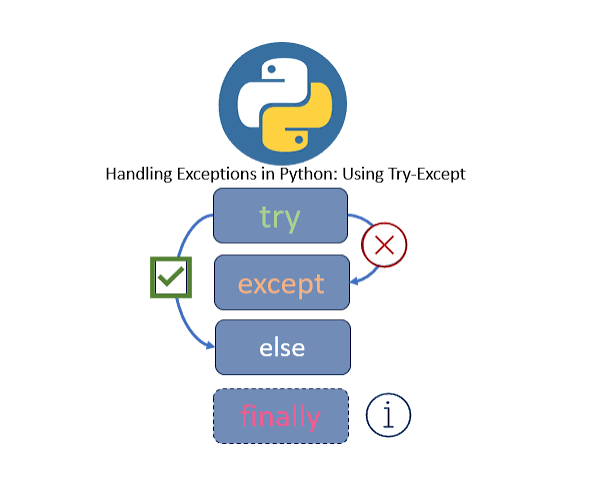

In [281]:
print"ali"

SyntaxError: Missing parentheses in call to 'print'. Did you mean print(...)? (830586636.py, line 1)

In [282]:
def bolme(x,y):
    return x/y


In [283]:
bolme(3,2)

1.5

In [284]:
bolme(3,0)

ZeroDivisionError: division by zero

In [307]:
bolme('a',3)

unsupported operand type(s) for /: 'str' and 'int'


In [316]:
def bolme(x,y):
    try:
        return x/y
    except ZeroDivisionError:
        return f"Payda 0 olamaz!!"
    except TypeError:
        return f"lütfen sayısal değerler giriniz"
    except Exception as e:
        return f"Bir hata oluştu: {e}"

In [309]:
bolme(3,4)

0.75

In [310]:
bolme(3,0)

'Payda 0 olamaz!!'

In [315]:
bolme(9, 'a')

'lütfen sayısal değerler giriniz'

In [318]:
bolme(3, None)

'lütfen sayısal değerler giriniz'

In [297]:
def test():
    try:
        1+0
    except:
        return 0
    else:
        return 1
    finally:
        return f'The end'

#fonksiyon çağıralım
test()

'The end'

In [298]:
def test():
    try:
        1+0
    except:
        return 0
    else:
        return 1
    finally:
        print('The end')

#fonksiyon çağıralım
test()

The end


1

In [319]:
def bolme(x,y):
    try:
        return x/y
    except ZeroDivisionError:
        return f"y sayısı 0 olamaz!!"
    except TypeError:
        return f"lütfen sayısal değerler giriniz"
    finally:
        print(f"Program bitti")

bolme(3,4)

Program bitti


0.75

In [300]:
bolme(3,0)

Program bitti


'y sayısı 0 olamaz!!'

In [301]:
# try tek başına kullanılmaz
# ya except ya da finally olmak zorunda
def bolme(x,y):
    try:
        return x/y

_IncompleteInputError: incomplete input (2388946576.py, line 5)

In [305]:
def bolme(x,y):
    try:
        return x/y
    finally:
        print(f"Program bitti")

In [304]:
bolme(2,3)

Program bitti


0.6666666666666666

In [306]:
def bolme(x,y):
    try:
        return x/y
    except Exception as e:
        print(e)

bolme(3,0)

division by zero


In [320]:
def bolme(x,y):
    try:
        return x/y
    except Exception as e:
        print(e)

bolme(3,'f')

unsupported operand type(s) for /: 'int' and 'str'
